## 1. Setup and customer table

Imports, file paths, and the customer table from `sql/06_last_order_date.sql`. The query returns one row per customer: country, first and last order date, and number of invoices (`n_orders`). Dates arrive from SQLite as text and are converted in the next step.

In [1]:
import os
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DB_PATH = "../data/processed/retail.db"   # notebooks/ sits one level below the project root
SQL_PATH = "../sql/06_last_order_date.sql"
FIG_DIR = "../reports/figures"

with open(SQL_PATH, encoding="utf-8") as f:
    query = f.read()

with sqlite3.connect(DB_PATH) as conn:
    customers = pd.read_sql_query(query, conn)

print(customers.shape)
print(customers.dtypes)
customers.head()

(4333, 5)
CustomerID          int64
Country               str
first_order_date      str
last_order_date       str
n_orders            int64
dtype: object


,CustomerID,Country,first_order_date,last_order_date,n_orders
0,12680,France,2011-08-18 15:44:00,2011-12-09 12:50:00,4
1,13113,United Kingdom,2010-12-08 13:21:00,2011-12-09 12:49:00,24
2,15804,United Kingdom,2011-05-25 10:12:00,2011-12-09 12:31:00,13
3,13777,United Kingdom,2010-12-01 16:01:00,2011-12-09 12:25:00,33
4,17581,United Kingdom,2010-12-02 14:47:00,2011-12-09 12:21:00,25


## 2. Days since last order

Dates are converted from text and cut to whole days. Days since last order is the reference date (2011-12-10, the day after the last valid order, 2011-12-09) minus each customer's last order date.

Sanity checks: no negative values, and a minimum of 1 day because the data ends on 2011-12-09. The distribution is right-skewed (median 51 days, mean 93), so a long tail of customers has been silent for months.

In [2]:
REFERENCE_DATE = pd.Timestamp("2011-12-10")   # last valid order is 2011-12-09

# Convert text to datetime and drop the time of day
for col in ["first_order_date", "last_order_date"]:
    customers[col] = pd.to_datetime(customers[col]).dt.normalize()

customers["days_since_last_order"] = (REFERENCE_DATE - customers["last_order_date"]).dt.days

print(customers["days_since_last_order"].describe().round(1))
print((customers["days_since_last_order"] < 0).sum(), "negative values")
print(customers[["CustomerID", "last_order_date", "days_since_last_order"]].head())

count    4333.0
mean       93.2
std       100.1
min         1.0
25%        18.0
50%        51.0
75%       143.0
max       374.0
Name: days_since_last_order, dtype: float64
0 negative values
   CustomerID last_order_date  days_since_last_order
0       12680      2011-12-09                      1
1       13113      2011-12-09                      1
2       15804      2011-12-09                      1
3       13777      2011-12-09                      1
4       17581      2011-12-09                      1


## 3. Order rhythm: gaps between orders

A churn cutoff only makes sense relative to how often customers normally reorder. Gaps are measured in days between consecutive *order days*, so several invoices on the same day count as one order. Each customer's first order day has no earlier order, so it has no gap.

There are 16,675 order days across 4,333 customers, which gives 12,342 gaps. Half of all gaps are 28 days or less and 75% are 58 days or less. The mean (45.8) is higher than the median because a few very long gaps (up to 366 days) pull it up.

In [3]:
with sqlite3.connect(DB_PATH) as conn:
    order_dates = pd.read_sql_query(
        """SELECT CustomerID, DATE(InvoiceDate) AS order_date
           FROM orders
           GROUP BY CustomerID, DATE(InvoiceDate)""", conn)

order_dates["order_date"] = pd.to_datetime(order_dates["order_date"])
order_dates = order_dates.sort_values(["CustomerID", "order_date"])

# Days between each order day and the previous one, within each customer
order_dates["gap_days"] = order_dates.groupby("CustomerID")["order_date"].diff().dt.days

n_days = order_dates.groupby("CustomerID").size()                # order days per customer
gap = order_dates.dropna(subset=["gap_days"])
per_customer = gap.groupby("CustomerID")["gap_days"].median()    # each customer's usual gap

print(order_dates.shape, "order days")
print(order_dates["gap_days"].isna().sum(), "rows with no gap")
print(order_dates["gap_days"].describe().round(1))

(16675, 3) order days
4333 rows with no gap
count    12342.0
mean        45.8
std         53.1
min          1.0
25%         12.0
50%         28.0
75%         58.0
max        366.0
Name: gap_days, dtype: float64


## 4. Typical reorder rhythm per customer

The pooled gaps above are dominated by frequent buyers, so each customer's own typical gap (the median of their gaps) is also computed. Customers with a single order day have no gap and are counted separately: they form the one-time buyer group.

Of 4,333 customers, 1,559 have a single order day and 2,774 have at least one gap. Pooled gaps have a 90th percentile of 111 days. Per customer, the median typical gap is 52.5 days, but the 75th percentile is 97.5 days, so about a quarter of repeat customers normally wait close to or beyond 90 days between orders. A flat 90-day cutoff is therefore reasonable as a main definition but will flag some slow-cycle customers while they are behaving normally. This is tested with a sensitivity check below.

Limitation: the data covers 12 months, so very long gaps cannot be observed and observed gaps skew short.

In [4]:
print(gap["gap_days"].quantile([0.5, 0.75, 0.9, 0.95]))
print(per_customer.describe().round(1))
print((n_days == 1).sum(), "customers with only one order day")

0.50     28.0
0.75     58.0
0.90    111.0
0.95    155.0
Name: gap_days, dtype: float64
count    2774.0
mean       75.1
std        68.1
min         1.0
25%        29.0
50%        52.5
75%        97.5
max       366.0
Name: gap_days, dtype: float64
1559 customers with only one order day


## 5. Buyer type and at-risk flag

Each customer is classified by order history and by recency.

- **Buyer type:** *one-time* if the customer has a single order day, *repeat* otherwise.
- **Status:** *at risk* if days since last order is at least 90 (`CUTOFF`), otherwise *active*.

One-time buyers are kept as a separate group because they have no ordering rhythm to compare against. A one-time buyer who ordered recently is a new customer, not a lost one.

Result: 1,463 of 4,333 customers (33.8%) are at risk. Of these, 892 (61%) are one-time buyers and 571 are repeat buyers. 57.2% of one-time buyers are at risk, against 20.6% of repeat buyers.

In [5]:
CUTOFF = 90   # days without an order that count as "at risk"

customers["n_order_days"] = customers["CustomerID"].map(n_days)   # from the gap section
customers["buyer_type"] = np.where(customers["n_order_days"] == 1, "one-time", "repeat")
customers["status"] = np.where(customers["days_since_last_order"] >= CUTOFF, "at risk", "active")

print(customers["status"].value_counts())
print(pd.crosstab(customers["buyer_type"], customers["status"]))

status
active     2870
at risk    1463
Name: count, dtype: int64
status      active  at risk
buyer_type                 
one-time       667      892
repeat        2203      571


## 6. Sensitivity of the cutoff

The 90-day cutoff is a judgement call, so the at-risk share is recomputed at 60 and 120 days.

| Cutoff | All customers | Repeat buyers | One-time buyers |
|---|---|---|---|
| 60 days | 45.8% | 31.6% | 71.1% |
| 90 days | 33.8% | 20.6% | 57.2% |
| 120 days | 28.4% | 15.1% | 52.1% |

The headline share depends on the cutoff (28% to 46%), so it is best reported as a range. The ranking does not change: one-time buyers are at risk far more often than repeat buyers at every cutoff. The repeat-buyer share is the most sensitive, because some repeat customers have long normal gaps.

In [6]:
repeat = customers["buyer_type"] == "repeat"

for c in [60, 90, 120]:
    at_risk = customers["days_since_last_order"] >= c
    print(f"Cutoff {c}: all {at_risk.mean():.1%} | "
          f"repeat {at_risk[repeat].mean():.1%} | "
          f"one-time {at_risk[~repeat].mean():.1%}")

Cutoff 60: all 45.8% | repeat 31.6% | one-time 71.1%
Cutoff 90: all 33.8% | repeat 20.6% | one-time 57.2%
Cutoff 120: all 28.4% | repeat 15.1% | one-time 52.1%


## 7. Revenue and average order value

Total revenue and invoice count per customer come from `sql/03_revenue_per_customer.sql` and are merged onto the customer table. Average order value is revenue divided by invoices.

Reconciliation checks: no customer is missing revenue, total revenue is £8,480,598.41 (the same total as in the `orders` table), and the invoice count from this query equals the one from the customer query for every customer.

Median average order value is used because order values are right-skewed. At-risk customers have a lower median order value in both groups (one-time: £235 vs £286, repeat: £265 vs £311), but the spread must be checked before treating this as a signal.

In [7]:
with open("../sql/03_revenue_per_customer.sql", encoding="utf-8") as f:
    rev_query = f.read()
with sqlite3.connect(DB_PATH) as conn:
    rev = pd.read_sql_query(rev_query, conn)

rev = rev.rename(columns={"n_orders": "n_invoices"}).drop(columns="Country")

# Drop columns from any earlier run so reruns cannot create _x / _y duplicates
stale = [c for c in customers.columns if c.startswith(("n_invoices", "total_revenue", "avg_order_value"))]
customers = customers.drop(columns=stale).merge(rev, on="CustomerID", how="left")
customers["avg_order_value"] = customers["total_revenue"] / customers["n_invoices"]

print(customers.shape)
print(customers["total_revenue"].isna().sum(), "missing revenue")
print(round(customers["total_revenue"].sum(), 2))
print((customers["n_orders"] == customers["n_invoices"]).all())
print(customers.groupby(["buyer_type", "status"])["avg_order_value"].median().round(2))

(4333, 12)
0 missing revenue
8480598.41
True
buyer_type  status 
one-time    active     285.56
            at risk    235.13
repeat      active     310.88
            at risk    264.86
Name: avg_order_value, dtype: float64


## 8. Other traits of at-risk customers: country and order frequency

**Country.** At-risk share is shown for the six countries with the most customers. The UK (33.7%) is close to the overall 33.8%. The other five range from 27.6% to 40.0%, but the smaller countries have only 20 to 94 customers, so one customer moves the share by roughly 1 to 5 points. These differences are within sampling noise, so country is not a reliable predictor of lapsing.

**Order frequency.** Customers are grouped by number of invoices (not order days, so the "1" band has 1,506 customers against 1,559 one-time buyers, because 53 customers placed several invoices on one day).

| Invoices | Customers | At risk |
|---|---|---|
| 1 | 1,506 | 57.2% |
| 2-3 | 1,331 | 34.5% |
| 4-9 | 1,110 | 12.1% |
| 10+ | 386 | 2.1% |

The largest drop comes between one invoice and two to three, so the second purchase is the key milestone. Part of this pattern is mechanical, because frequent buyers have had more chances to order recently. It should be read as "customers who reach four or more orders are rarely inactive", not as a causal effect.

In [8]:
# At-risk share for the six countries with the most customers
top_countries = customers["Country"].value_counts().head(6).index
print(customers[customers["Country"].isin(top_countries)]
      .groupby("Country")["status"].apply(lambda s: (s == "at risk").mean()).round(3))

# At-risk share by number of invoices
customers["freq_band"] = pd.cut(customers["n_invoices"], [0, 1, 3, 9, 1000],
                                labels=["1", "2-3", "4-9", "10+"])
print(customers.groupby("freq_band", observed=True)["status"]
      .apply(lambda s: (s == "at risk").mean()).round(3))
print(customers["freq_band"].value_counts().sort_index())

Country
Belgium           0.304
France            0.299
Germany           0.277
Spain             0.276
Switzerland       0.400
United Kingdom    0.337
Name: status, dtype: float64
freq_band
1      0.572
2-3    0.345
4-9    0.121
10+    0.021
Name: status, dtype: float64
freq_band
1      1506
2-3    1331
4-9    1110
10+     386
Name: count, dtype: int64


## 9. Customer segments and revenue contribution

Customers are split into one-time and repeat buyers, and each group's contribution to revenue is compared.

| Segment | Customers | Share of customers | Revenue | Share of revenue | Median revenue |
|---|---|---|---|---|---|
| One-time | 1,559 | 36.0% | £651,748 | 7.7% | £261 |
| Repeat | 2,774 | 64.0% | £7,828,850 | 92.3% | £1,168 |

Repeat buyers carry the business: they are under two thirds of customers but over 90% of revenue. The retention problem therefore has two faces. By headcount, it is mostly one-time buyers who never returned. By revenue, it is the repeat buyers who have gone quiet.

Revenue held by at-risk customers is £937,999 (11.1% of the total): £369,379 from one-time buyers and £568,620 from repeat buyers. These are past purchases, not a forecast of what would be lost or recovered.

In [9]:
seg = customers.groupby("buyer_type").agg(
    customers=("CustomerID", "count"),
    revenue=("total_revenue", "sum"),
    median_revenue=("total_revenue", "median"))
seg["pct_customers"] = (seg["customers"] / seg["customers"].sum() * 100).round(1)
seg["pct_revenue"] = (seg["revenue"] / seg["revenue"].sum() * 100).round(1)
print(seg.round(2))

# Revenue held by each group, split by status
print(customers.groupby(["buyer_type", "status"])["total_revenue"].sum().round(0))

            customers     revenue  median_revenue  pct_customers  pct_revenue
buyer_type                                                                   
one-time         1559   651747.94          261.11           36.0          7.7
repeat           2774  7828850.47         1167.82           64.0         92.3
buyer_type  status 
one-time    active      282369.0
            at risk     369379.0
repeat      active     7260231.0
            at risk     568620.0
Name: total_revenue, dtype: float64


## 10. Revenue by country

Revenue per country comes from `sql/05_revenue_by_country.sql` (identified customers only). "Unspecified" and "European Community" are not countries and are excluded from the chart only (together about 0.04% of revenue). Because the UK dominates, the chart has two panels: the top 10 countries, and the top 10 without the UK. Each bar is labelled with its number of customers.

The UK accounts for about 82% of revenue. The Netherlands (one account, 98% of its revenue) and Ireland (two accounts, 98%) rank second and third, so those markets depend on very few customers.

          Country  n_customers  total_revenue  pct_of_revenue
0  United Kingdom         3915     6985393.99           82.37
1     Netherlands            9      283889.34            3.35
2         Ireland            3      257296.56            3.03
3         Germany           94      205569.89            2.42
4          France           87      183891.68            2.17
8480598.41 total


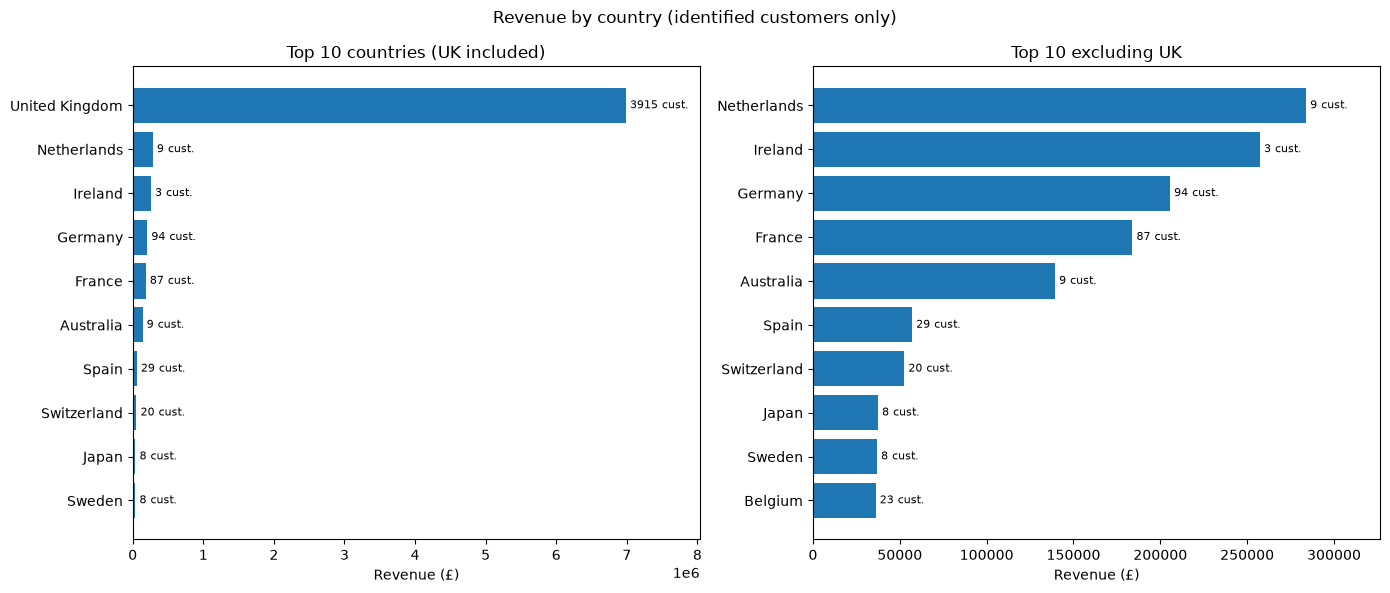

In [10]:
with open("../sql/05_revenue_by_country.sql", encoding="utf-8") as f:
    country_query = f.read()
with sqlite3.connect(DB_PATH) as conn:
    country = pd.read_sql_query(country_query, conn)

print(country[["Country", "n_customers", "total_revenue", "pct_of_revenue"]].head(5))
print(round(country["total_revenue"].sum(), 2), "total")

# Exclude non-countries from the chart only (decided in profiling)
country = country[~country["Country"].isin(["Unspecified", "European Community"])]

panels = [
    (country.head(10), "Top 10 countries (UK included)"),
    (country[country["Country"] != "United Kingdom"].head(10), "Top 10 excluding UK"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (data, title) in zip(axes, panels):
    data = data.sort_values("total_revenue")
    bars = ax.barh(data["Country"], data["total_revenue"])
    ax.bar_label(bars, labels=[f"{n} cust." for n in data["n_customers"]], padding=3, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("Revenue (£)")
    ax.margins(x=0.15)   # room for the labels

fig.suptitle("Revenue by country (identified customers only)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/revenue_by_country.png", dpi=150)
plt.show()

## 11. Top 10 products by revenue

Revenue per product, summed over all invoice lines, grouped by stock code. The top 10 products earn £675,645 (8.0% of total revenue). The largest, Regency Cakestand 3 Tier, earns about 3.6 times as much as the tenth.

Where one stock code carries more than one description (for example 85123A, white vs cream), the label shows the most frequent one, and revenue covers all variants.

By comparison, the top 10 customers hold 16.5% of revenue, so the business depends more on a few customers than on a few products.

675644.69 top-10 total


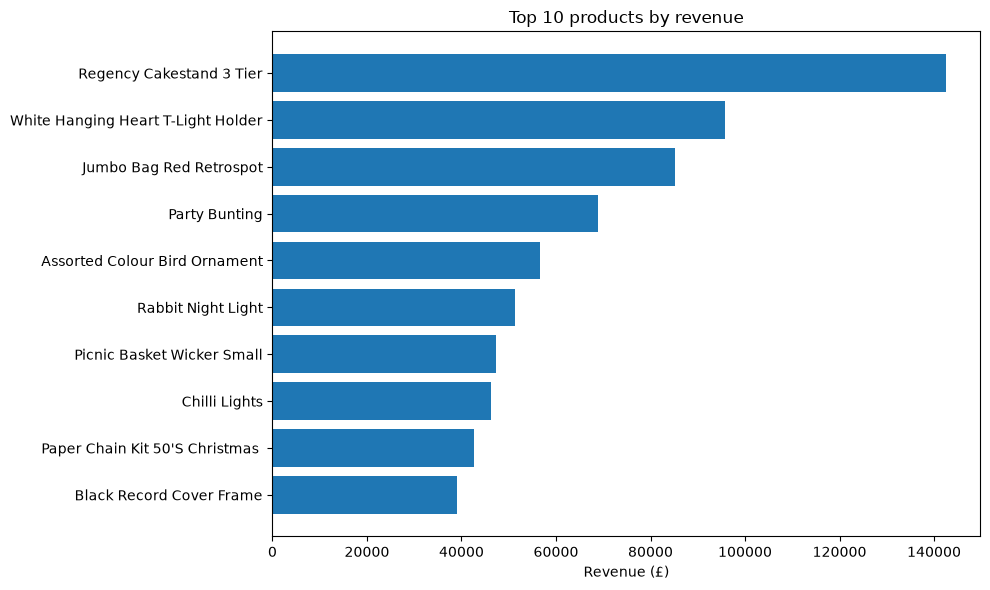

In [11]:
with sqlite3.connect(DB_PATH) as conn:
    top_products = pd.read_sql_query("""
        SELECT p.StockCode, p.Description,
               ROUND(SUM(o.Quantity * o.UnitPrice), 2) AS total_revenue
        FROM orders o
        JOIN products p ON o.StockCode = p.StockCode
        GROUP BY p.StockCode, p.Description
        ORDER BY total_revenue DESC
        LIMIT 10""", conn)

print(round(top_products["total_revenue"].sum(), 2), "top-10 total")

data = top_products.sort_values("total_revenue")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(data["Description"].str.title(), data["total_revenue"])
ax.set_xlabel("Revenue (£)")
ax.set_title("Top 10 products by revenue")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/top_products_revenue.png", dpi=150)
plt.show()

## 12. Distribution of days since last order

The histogram shows how long customers have been silent, in 30-day bins. The dashed line marks the 90-day cutoff, which sits on a bin edge, so every bar to its right is an at-risk customer.

The distribution is right-skewed. The 0-29 day bin is the tallest, with 1,570 customers (36% of the total), and 2,870 customers (66%) ordered within the last 90 days. A long, fairly flat tail of 1,463 customers (34%) stretches out to 374 days, which is why the mean (93 days) is well above the median (51 days).

The last bin (360-389 days) rises to 98 customers from 58 in the bin before. These are customers whose last order was in the first weeks of the data. The chart cannot show whether they are lost customers or customers whose history began before the data.

{'0-29': 1570, '30-59': 779, '60-89': 521, '90-119': 231, '120-149': 178, '150-179': 183, '180-209': 165, '210-239': 141, '240-269': 171, '270-299': 123, '300-329': 115, '330-359': 58, '360-389': 98}
2870 customers under 90 days | 1463 at 90+ days


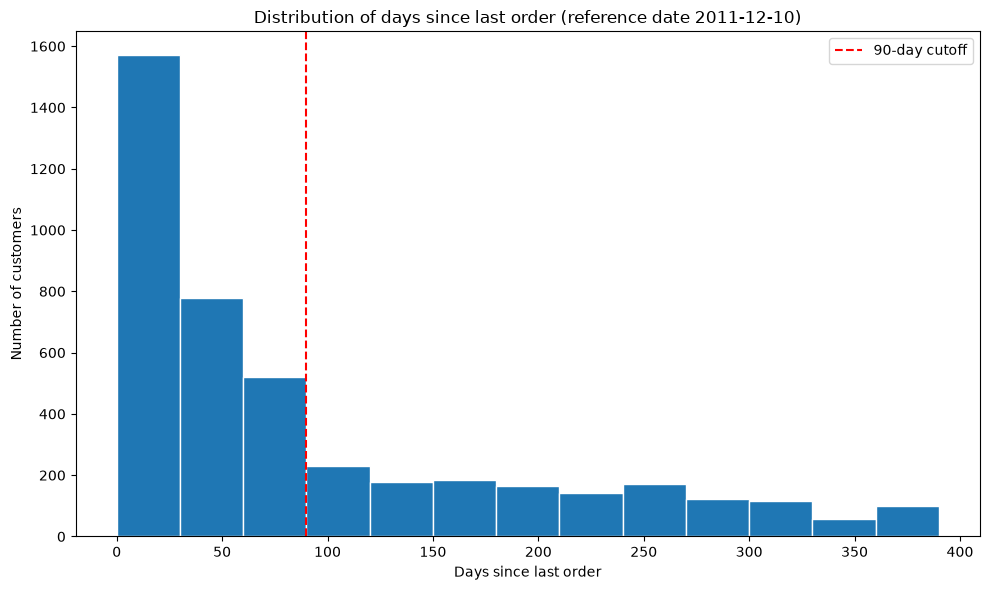

In [12]:
bins = range(0, 400, 30)
counts, _ = np.histogram(customers["days_since_last_order"], bins=bins)
print({f"{b}-{b + 29}": int(n) for b, n in zip(bins[:-1], counts)})
print(counts[:3].sum(), "customers under 90 days |", counts[3:].sum(), "at 90+ days")

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(customers["days_since_last_order"], bins=bins, edgecolor="white")
ax.axvline(CUTOFF, color="red", linestyle="--", label=f"{CUTOFF}-day cutoff")
ax.set_xlabel("Days since last order")
ax.set_ylabel("Number of customers")
ax.set_title(f"Distribution of days since last order (reference date {REFERENCE_DATE.date()})")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/days_since_last_order.png", dpi=150)
plt.show()

## 13. Average order value: at-risk vs active customers

Median average order value is compared between at-risk and active customers, split by buyer type. The split matters because at-risk customers are mostly one-time buyers, and a single pooled comparison would blur the two groups.

| Buyer type | Active | At risk | Difference |
|---|---|---|---|
| One-time | £286 | £235 | -18% |
| Repeat | £311 | £265 | -15% |

At-risk customers have a lower median order value in both groups. The bars start at zero so the gap is not exaggerated. The spread below shows how much the groups overlap, so this should be read as a weak signal, not a rule for identifying who will lapse. These are differences in medians, so they show association, not cause: a customer losing interest may place smaller orders before stopping.

Spread (25th to 75th percentile of order value): one-time active £165-431 against at risk £138-370, and repeat active £204-448 against at risk £159-406. The median gap is about £46 to £50, while each group's middle half spans over £230, so the ranges overlap heavily. Order value alone does not identify who will lapse.

status      active  at risk
buyer_type                 
one-time    285.56   235.13
repeat      310.88   264.86
status
active     306.04
at risk    248.10
Name: avg_order_value, dtype: float64
                     0.25   0.50   0.75
buyer_type status                      
one-time   active   165.0  286.0  431.0
           at risk  138.0  235.0  370.0
repeat     active   204.0  311.0  448.0
           at risk  159.0  265.0  406.0


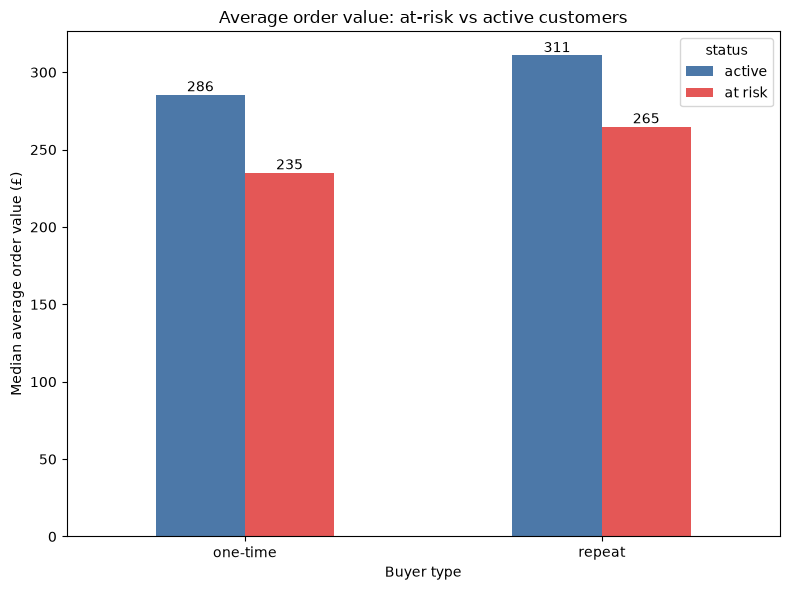

In [13]:
aov = (customers.groupby(["buyer_type", "status"])["avg_order_value"]
       .median().unstack("status")[["active", "at risk"]])
print(aov.round(2))
print(customers.groupby("status")["avg_order_value"].median().round(2))

# Spread: 25th, 50th and 75th percentile of order value per group
print(customers.groupby(["buyer_type", "status"])["avg_order_value"]
      .quantile([0.25, 0.5, 0.75]).unstack().round(0))

fig, ax = plt.subplots(figsize=(8, 6))
aov.plot(kind="bar", ax=ax, rot=0, color=["#4C78A8", "#E45756"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
ax.set_xlabel("Buyer type")
ax.set_ylabel("Median average order value (£)")
ax.set_title("Average order value: at-risk vs active customers")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/aov_at_risk_vs_active.png", dpi=150)
plt.show()

In [14]:
print(customers.groupby(["buyer_type", "status"])["avg_order_value"]
      .quantile([0.25, 0.5, 0.75]).unstack().round(0))

                     0.25   0.50   0.75
buyer_type status                      
one-time   active   165.0  286.0  431.0
           at risk  138.0  235.0  370.0
repeat     active   204.0  311.0  448.0
           at risk  159.0  265.0  406.0


In [15]:
lapsed = customers[(customers["buyer_type"] == "repeat") & (customers["status"] == "at risk")]
print(lapsed.nlargest(10, "total_revenue")[["CustomerID", "Country", "n_invoices", "days_since_last_order", "total_revenue"]])
print(round(lapsed.nlargest(10, "total_revenue")["total_revenue"].sum() / lapsed["total_revenue"].sum(), 3))



      CustomerID         Country  n_invoices  days_since_last_order  \
2967       16180  United Kingdom           8                    101   
3964       13093  United Kingdom           8                    276   
3340       12980  United Kingdom           9                    158   
3068       13027  United Kingdom           6                    114   
2878       15939  United Kingdom          14                     90   
3365       16553  United Kingdom          12                    164   
4303       17850  United Kingdom          34                    373   
3860       15032  United Kingdom           3                    257   
3233       13802  United Kingdom           3                    139   
3357       14016         Ireland           4                    162   

      total_revenue  
2967       10254.18  
3964        7832.47  
3340        7374.90  
3068        6912.00  
2878        6100.01  
3365        5719.82  
4303        5391.21  
3860        4959.10  
3233        4599.42 

## 14. Customer concentration

Customers ranked by total revenue. The top 10 customers earn £1,394,737 (16.45% of revenue), from 0.2% of customers. The same ten customers lead after the cleaning rebuild, and 16029 is now tenth. By comparison, the top 10 products hold 8.0%, so the business depends more on a few customers than on a few products.

In [16]:
top10 = customers.nlargest(10, "total_revenue")
print(top10[["CustomerID", "total_revenue"]])
print(round(top10["total_revenue"].sum() / customers["total_revenue"].sum() * 100, 2))

      CustomerID  total_revenue
103        14646      279138.02
12         18102      259657.30
571        17450      194550.79
54         14911      136275.72
1403       12415      124564.53
664        14156      116729.63
209        17511       91062.38
359        16684       66653.56
313        13694       65039.62
1895       16029       61065.45
16.45


## 15. Lapsed repeat buyers: where the revenue risk sits

Repeat buyers with 90 or more days since their last order are the group with the most revenue at stake: 571 customers with £568,620 of past spend (6.7% of total revenue).

- **Concentration:** the top 10 hold only 11.2%. It takes 114 customers to reach half of this value and 295 to reach 80%. The risk is broad, not concentrated in a few accounts.
- **Recency:** 353 customers (62%) lapsed 90 to 180 days ago and hold £388,054 (68%) of the value. Only 53 customers (9% of the value) have been silent for 271 days or more.

These figures are past spend, not a forecast of what could be recovered.

In [17]:
lapsed = (customers[(customers["buyer_type"] == "repeat") & (customers["status"] == "at risk")]
          .sort_values("total_revenue", ascending=False))
lapsed["cum_share"] = lapsed["total_revenue"].cumsum() / lapsed["total_revenue"].sum()

print(len(lapsed), round(lapsed["total_revenue"].sum(), 2))
for p in [0.5, 0.8]:
    print(f"{p:.0%} of lapsed revenue: {(lapsed['cum_share'] < p).sum() + 1} customers")

lapsed["recency_band"] = pd.cut(lapsed["days_since_last_order"], [89, 120, 180, 270, 400],
                                labels=["90-120", "121-180", "181-270", "271+"])
print(lapsed.groupby("recency_band", observed=True)
      .agg(n=("CustomerID", "count"), revenue=("total_revenue", "sum")).round(0))

571 568619.51
50% of lapsed revenue: 114 customers
80% of lapsed revenue: 295 customers
                n   revenue
recency_band               
90-120        160  194737.0
121-180       193  193317.0
181-270       165  128221.0
271+           53   52344.0


## 16. Overdue against each customer's own rhythm (first pass)

A flat 90 days ignores that customers reorder at different speeds. The overdue ratio is days since last order divided by the customer's usual gap (the median of their own gaps). A ratio above 1 means later than usual.

First pass on all 571 lapsed repeat buyers: 79 are not yet past their own usual gap, 236 are more than three times overdue, and the median ratio is 2.4. This pass includes customers whose usual gap rests on a single gap, so it is revisited in section 18.

In [18]:
lapsed["usual_gap"] = lapsed["CustomerID"].map(per_customer)
lapsed["overdue_ratio"] = lapsed["days_since_last_order"] / lapsed["usual_gap"]

print((lapsed["overdue_ratio"] < 1).sum(), "lapsed customers not yet past their own usual gap")
print((lapsed["overdue_ratio"] > 3).sum(), "lapsed customers more than 3x overdue")
print(lapsed["overdue_ratio"].describe().round(1))

79 lapsed customers not yet past their own usual gap
236 lapsed customers more than 3x overdue
count    571.0
mean       7.7
std       26.0
min        0.4
25%        1.4
50%        2.4
75%        5.0
max      373.0
Name: overdue_ratio, dtype: float64


## 17. Personal-contact tier (first pass, superseded)

Top 114 customers by value (the group holding half of lapsed revenue), late against their own rhythm, and lapsed 180 days or less. This gives 75 customers holding £189,499 (33.3%). The overdue filter relies on the weak ratios noted above, so this tier is replaced by the guarded version in section 19.

In [19]:
lapsed["value_rank"] = range(1, len(lapsed) + 1)   # lapsed is sorted by revenue, highest first

personal = ((lapsed["value_rank"] <= 114)
            & (lapsed["overdue_ratio"] > 1)
            & (lapsed["days_since_last_order"] <= 180))

print(personal.sum(), "customers in the personal tier")
print(round(lapsed.loc[personal, "total_revenue"].sum(), 2), "past revenue in that tier")
print(round(lapsed.loc[personal, "total_revenue"].sum() / lapsed["total_revenue"].sum() * 100, 1), "% of lapsed revenue")

75 customers in the personal tier
189499.41 past revenue in that tier
33.3 % of lapsed revenue


## 18. How reliable is a customer's "usual gap"?

Customer 17850 shows the problem: 34 invoices on only two order days (1 and 2 December 2010). Its usual gap is a single one-day gap, so its overdue ratio is 373. It is a burst of orders, not a rhythm.

This is common among lapsed repeat buyers: 319 of 571 (56%, £226,320) have only two order days, so their usual gap is a single gap. The own-rhythm comparison is only reliable for the other 252 customers, with three or more order days. For these:

- 16 (6%) were not yet past their own usual gap, so the flat rule gave few false alarms.
- 107 (42%) were more than three times overdue, a strong sign they have really stopped.
- The median ratio is 2.6.

Of the 75 customers in the first-pass tier, 12 had only two order days.

In [20]:
print(customers.loc[customers["CustomerID"] == 17850,
      ["first_order_date", "last_order_date", "n_order_days", "n_invoices", "total_revenue"]])

     first_order_date last_order_date  n_order_days  n_invoices  total_revenue
4303       2010-12-01      2010-12-02             2          34        5391.21


In [21]:
two_day = lapsed[lapsed["CustomerID"].map(n_days) == 2]
print(len(two_day), "lapsed customers with only 2 order days")
print(round(two_day["total_revenue"].sum(), 2), "their past revenue")

319 lapsed customers with only 2 order days
226320.46 their past revenue


In [22]:
lapsed["n_order_days"] = lapsed["CustomerID"].map(n_days)
reliable = lapsed[lapsed["n_order_days"] >= 3]

print(len(reliable), "lapsed customers with 3+ order days")
print((reliable["overdue_ratio"] < 1).sum(), "not yet past their own gap")
print((reliable["overdue_ratio"] > 3).sum(), "more than 3x overdue")
print(reliable["overdue_ratio"].describe().round(1))

print((personal & (lapsed["n_order_days"] == 2)).sum(), "of the 75 personal-tier customers have only 2 order days")

252 lapsed customers with 3+ order days
16 not yet past their own gap
107 more than 3x overdue
count    252.0
mean       5.3
std       10.8
min        0.7
25%        1.7
50%        2.6
75%        4.7
max      134.0
Name: overdue_ratio, dtype: float64
12 of the 75 personal-tier customers have only 2 order days


## 19. Personal-contact tier (final)

Customers with two order days have no reliable rhythm, so for them the flat 90-day rule is used and the overdue filter is skipped. Customers with three or more order days must be later than their own usual gap.

The tier is: top 114 by value, lapsed 180 days or less, and overdue by the rule above. It contains **79 customers holding £198,505 (34.9% of lapsed revenue)**, about £2,500 each. Tier size is a capacity decision. A smaller team could limit it to the highest-value customers in this group.

In [23]:
overdue_ok = (lapsed["n_order_days"] == 2) | (lapsed["overdue_ratio"] > 1)
personal2 = ((lapsed["value_rank"] <= 114)
             & overdue_ok
             & (lapsed["days_since_last_order"] <= 180))

print(personal2.sum(), "customers in the guarded personal tier")
print(round(lapsed.loc[personal2, "total_revenue"].sum(), 2), "past revenue")
print(round(lapsed.loc[personal2, "total_revenue"].sum() / lapsed["total_revenue"].sum() * 100, 1), "% of lapsed revenue")

79 customers in the guarded personal tier
198504.59 past revenue
34.9 % of lapsed revenue


## Conclusions

- 1,463 of 4,333 customers (33.8%) have not ordered in 90+ days (28% to 46% across 120 and 60 days). 61% of them are one-time buyers.
- Repeat buyers are 64% of customers and 92.3% of revenue. 571 lapsed repeat buyers hold £568,620 of past spend, spread broadly.
- A customer's usual reorder gap is only reliable with three or more order days, so the own-rhythm rule applies to those customers.

Full findings, recommendations and limitations: `reports/findings.md`.